# ICSE'26 — Results Dashboard

Loads all available result files from `results/icse_26/` and renders the full set of
visualizations.  **Runs that have not finished yet are skipped gracefully** — re-execute
the notebook as experiments complete to pick up new results.

Sections:
1. [Status overview](#1.-Status-overview)
2. [Pareto fronts per task](#2.-Pareto-fronts-per-task)
3. [Baseline comparison](#3.-Baseline-comparison)
4. [Compression ratio vs. performance](#4.-Compression-ratio-vs.-performance)
5. [Convergence (generation history)](#5.-Convergence)
6. [Operator usage](#6.-Operator-usage)
7. [Fitting report summary](#7.-Fitting-report-summary)
8. [NSGA-II vs MAB comparison](#8.-NSGA-II-vs-MAB-comparison)
9. [Transferability analysis](#9.-Transferability-analysis)


In [8]:
# ── Imports ───────────────────────────────────────────────────────────────────
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

# ── Configuration — edit these if you move files or add models ─────────────────
RESULTS_DIR = Path("../results/icse_26/gpt-5.4-mini-2026-03-17")

# NSGA-II primary runs
RUNS = [
    "mbpp_instruct_nsga2",
    "mmlu_pro_cs_nsga2",
    "gsm8k_cot_nsga2",
    "bbh_logical_deduction_nsga2",
    "musr_murder_mysteries_nsga2",
]

# MAB primary runs (same tasks, self-contained approach)
MAB_RUNS = [
    "mbpp_instruct_mab",
    "mmlu_pro_cs_mab",
    "gsm8k_cot_mab",
    "bbh_logical_deduction_mab",
    "musr_murder_mysteries_mab",
]

TASK_LABELS = {
    "mbpp_instruct_nsga2":           "MBPP-Instruct",
    "mmlu_pro_cs_nsga2":             "MMLU-Pro (CS)",
    "gsm8k_cot_nsga2":               "GSM8K-CoT",
    "bbh_logical_deduction_nsga2":   "BBH-Logical",
    "musr_murder_mysteries_nsga2":   "MuSR-Murder",
    "mbpp_instruct_mab":             "MBPP-Instruct",
    "mmlu_pro_cs_mab":               "MMLU-Pro (CS)",
    "gsm8k_cot_mab":                 "GSM8K-CoT",
    "bbh_logical_deduction_mab":     "BBH-Logical",
    "musr_murder_mysteries_mab":     "MuSR-Murder",
}

# Colour palette — one entry per baseline method
BASELINE_STYLE = {
    "no_compression":      {"color": "#555555", "marker": "D", "zorder": 5},
    "all_transformations": {"color": "#e06c75", "marker": "s", "zorder": 4},
    "random_search":       {"color": "#d19a66", "marker": "^", "zorder": 4},
    "multi_armed_bandit":  {"color": "#e5c07b", "marker": "*", "zorder": 4},
    "summarization":       {"color": "#c678dd", "marker": "P", "zorder": 4},
    "truncated_prompt":    {"color": "#61afef", "marker": "v", "zorder": 4},
    "random_deletion":     {"color": "#56b6c2", "marker": "X", "zorder": 4},
}

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
print("Config ready.")


Config ready.


In [9]:
# ── Load results ──────────────────────────────────────────────────────────────
def load_results(results_dir: Path, runs: list[str]) -> dict:
    """Load every available JSON result file; silently skip missing ones."""
    loaded = {}
    for name in runs:
        path = results_dir / f"{name}.json"
        if path.exists():
            try:
                with open(path) as fh:
                    loaded[name] = json.load(fh)
            except json.JSONDecodeError as exc:
                print(f"  ⚠ {name}: JSON parse error ({exc}) — file may still be writing")
    return loaded


def load_transfer_results(results_dir: Path, pairs: list[tuple]) -> dict:
    """Load transferability result files; returns {(source, target): data}."""
    loaded = {}
    for source, target in pairs:
        path = results_dir / f"transfer_{source}_to_{target}.json"
        if path.exists():
            try:
                with open(path) as fh:
                    loaded[(source, target)] = json.load(fh)
            except json.JSONDecodeError as exc:
                print(f"  ⚠ transfer {source}→{target}: JSON error ({exc})")
    return loaded


results     = load_results(RESULTS_DIR, RUNS)
mab_results = load_results(RESULTS_DIR, MAB_RUNS)

TRANSFER_PAIRS = [
    ("gsm8k_cot_nsga2", "bbh_logical_deduction_nsga2"),
    ("bbh_logical_deduction_nsga2", "gsm8k_cot_nsga2"),
]
transfer_results = load_transfer_results(RESULTS_DIR, TRANSFER_PAIRS)

print(f"NSGA-II: {len(results)}/{len(RUNS)} runs loaded")
print(f"MAB:     {len(mab_results)}/{len(MAB_RUNS)} runs loaded")
print(f"Transfer: {len(transfer_results)}/{len(TRANSFER_PAIRS)} pairs loaded")


NSGA-II: 3/5 runs loaded
MAB:     2/5 runs loaded
Transfer: 0/2 pairs loaded


## 1. Status overview

In [10]:
rows = []
for name in RUNS:
    label = TASK_LABELS.get(name, name)
    mab_name = name.replace("_nsga2", "_mab")
    for alg, res_dict, run_key in [("NSGA-II", results, name), ("MAB", mab_results, mab_name)]:
        if run_key not in res_dict:
            rows.append({
                "Task": label, "Algorithm": alg, "Status": "⏳ pending",
                "Pareto solutions": "—", "Baselines": "—",
                "Search (min)": "—", "Eval (min)": "—",
            })
            continue
        r = res_dict[run_key]
        rows.append({
            "Task": label, "Algorithm": alg,
            "Status": "✓ complete",
            "Pareto solutions": len(r["pareto_solutions"]),
            "Baselines": len(r["baselines"]),
            "Search (min)": f"{r['search_elapsed_seconds']/60:.1f}",
            "Eval (min)": f"{r['eval_elapsed_seconds']/60:.1f}",
        })

df_status = pd.DataFrame(rows)
df_status.set_index(["Task", "Algorithm"], inplace=True)
display(df_status)


Status Pareto solutions Baselines Search (min)  \
Task          Algorithm                                                       
MBPP-Instruct NSGA-II    ✓ complete               50         6        232.8   
              MAB        ✓ complete                6         6        175.3   
MMLU-Pro (CS) NSGA-II    ✓ complete               50         6         70.8   
              MAB        ✓ complete                2         6        113.5   
GSM8K-CoT     NSGA-II    ✓ complete               50         6         41.2   
              MAB         ⏳ pending                —         —            —   
BBH-Logical   NSGA-II     ⏳ pending                —         —            —   
              MAB         ⏳ pending                —         —            —   
MuSR-Murder   NSGA-II     ⏳ pending                —         —            —   
              MAB         ⏳ pending                —         —            —   

                        Eval (min)  
Task          Algorithm             
MBPP-Instruct NSGA-II         16.5  
              MAB              3.4  
MMLU-Pro (CS) NSGA-II         28.8  
              MAB             11.1  
GSM8K-CoT     NSGA-II         12.7  
              MAB                —  
BBH-Logical   NSGA-II            —  
              MAB                —  
MuSR-Murder   NSGA-II            —  
              MAB                —

## 2. Pareto fronts per task

Each subplot shows the NSGA-II Pareto front (blue line) and all baselines (coloured markers).
**x-axis**: average tokens after compression (lower = more compressed).  
**y-axis**: average task performance on the held-out **test** split (higher = better).

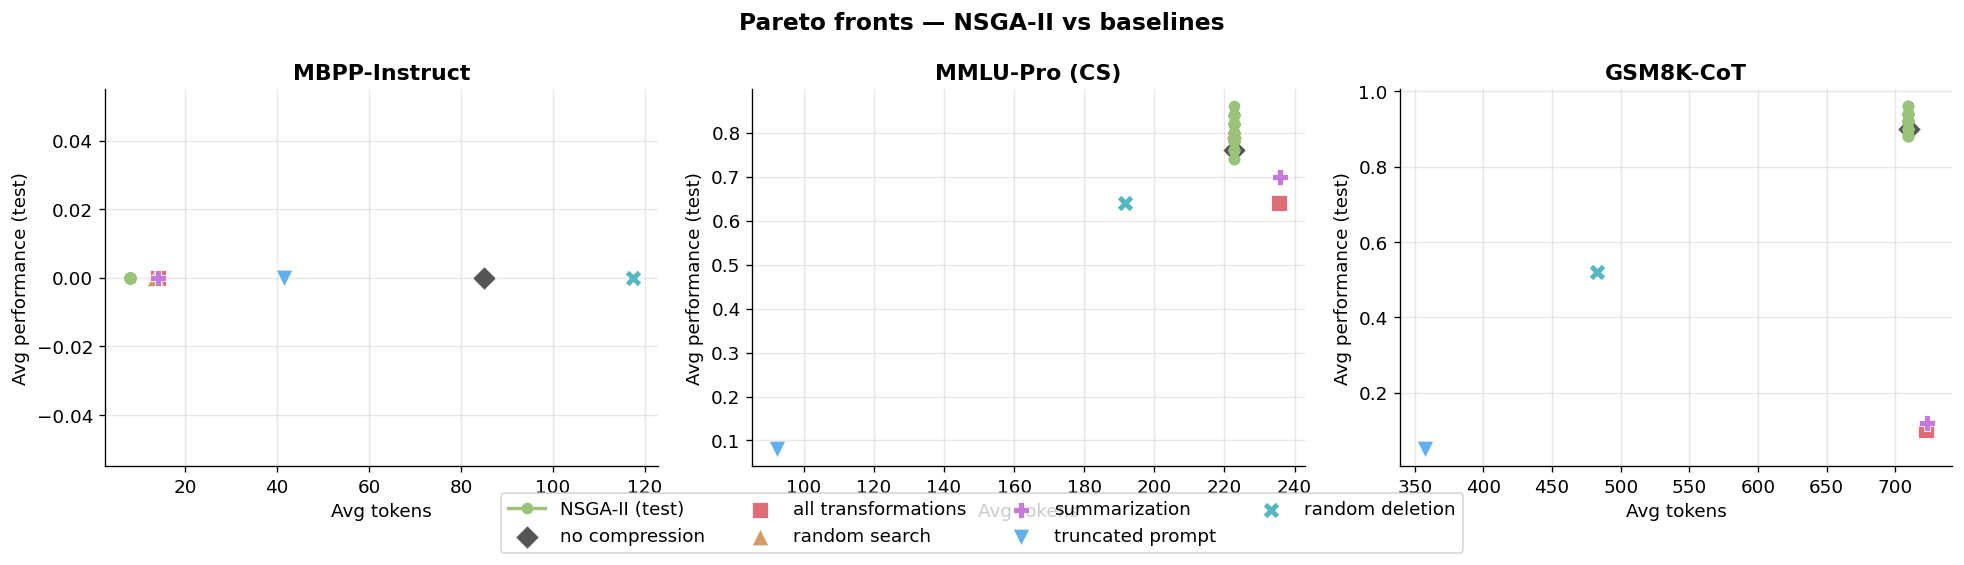

In [11]:
def _pareto_xy(solutions: list[dict], split: str = "test") -> tuple:
    """Return (tokens, performance) arrays for a list of SolutionEval dicts."""
    tok_key  = f"{split}_avg_tokens"
    perf_key = f"{split}_avg_performance"
    tok  = [s[tok_key]  for s in solutions if s.get(tok_key)  is not None]
    perf = [s[perf_key] for s in solutions if s.get(perf_key) is not None]
    if not tok:
        # fall back to search-phase values
        tok  = [s["search_avg_tokens"]      for s in solutions]
        perf = [s["search_avg_performance"] for s in solutions]
        return np.array(tok), np.array(perf), True
    return np.array(tok), np.array(perf), False


completed = [n for n in RUNS if n in results]
if not completed:
    print("No completed runs yet — check back once experiments start finishing.")
else:
    ncols = min(3, len(completed))
    nrows = (len(completed) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows), squeeze=False)

    for idx, name in enumerate(completed):
        ax = axes[idx // ncols][idx % ncols]
        r  = results[name]

        # ── NSGA-II Pareto front ──────────────────────────────────────────
        tok, perf, search_only = _pareto_xy(r["pareto_solutions"])
        order = np.argsort(tok)
        label = "NSGA-II" + (" (search)" if search_only else " (test)")
        ax.plot(tok[order], perf[order], "o-", color="#98c379", lw=2,
                markersize=6, label=label, zorder=6)

        # ── Baselines ─────────────────────────────────────────────────────
        for bl in r["baselines"]:
            bname = bl["name"]
            bt = bl.get("test_avg_tokens")       or bl["search_avg_tokens"]
            bp = bl.get("test_avg_performance") or bl["search_avg_performance"]
            style = BASELINE_STYLE.get(bname, {"color": "gray", "marker": "o", "zorder": 3})
            ax.scatter(bt, bp, s=100, label=bname.replace("_", " "),
                       color=style["color"], marker=style["marker"],
                       zorder=style["zorder"], edgecolors="white", linewidths=0.5)

        ax.set_title(TASK_LABELS.get(name, name), fontweight="bold")
        ax.set_xlabel("Avg tokens")
        ax.set_ylabel("Avg performance (test)")

    # Hide unused subplots
    for idx in range(len(completed), nrows * ncols):
        axes[idx // ncols][idx % ncols].set_visible(False)

    # Shared legend below all subplots
    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4,
               bbox_to_anchor=(0.5, -0.04), frameon=True)
    fig.suptitle("Pareto fronts — NSGA-II vs baselines", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

## 3. Baseline comparison

Test-split performance and token count for every baseline and the best NSGA-II Pareto
solution (highest performance), grouped by task.

In [12]:
def _best_pareto(r: dict) -> dict | None:
    """Return the Pareto solution with the highest test performance."""
    sols = [s for s in r["pareto_solutions"]
            if s.get("test_avg_performance") is not None]
    if not sols:
        sols = r["pareto_solutions"]
    if not sols:
        return None
    return max(sols, key=lambda s: s.get("test_avg_performance") or s["search_avg_performance"])


table_rows = []
for name in RUNS:
    if name not in results:
        continue
    r     = results[name]
    label = TASK_LABELS.get(name, name)

    # NSGA-II best
    best = _best_pareto(r)
    if best:
        table_rows.append({
            "Task": label, "Method": "NSGA-II (best perf)",
            "Test perf": best.get("test_avg_performance") or best["search_avg_performance"],
            "Test tokens": best.get("test_avg_tokens") or best["search_avg_tokens"],
        })

    for bl in r["baselines"]:
        table_rows.append({
            "Task": label,
            "Method": bl["name"].replace("_", " "),
            "Test perf":   bl.get("test_avg_performance") or bl["search_avg_performance"],
            "Test tokens": bl.get("test_avg_tokens")       or bl["search_avg_tokens"],
        })

if table_rows:
    df_bl = pd.DataFrame(table_rows)
    df_bl["Test perf"]   = df_bl["Test perf"].map("{:.4f}".format)
    df_bl["Test tokens"] = df_bl["Test tokens"].map("{:.1f}".format)
    display(df_bl.set_index(["Task", "Method"]))
else:
    print("No data yet.")

Test perf Test tokens
Task          Method                                   
MBPP-Instruct NSGA-II (best perf)    0.0000         8.0
              no compression         0.0000        85.0
              all transformations    0.0000        14.0
              random search          0.0000        13.4
              summarization          0.0000        14.0
              truncated prompt       0.0000        41.4
              random deletion        0.0000       117.3
MMLU-Pro (CS) NSGA-II (best perf)    0.8600       222.6
              no compression         0.7600       222.8
              all transformations    0.6400       235.6
              random search          0.8037       222.6
              summarization          0.7000       235.8
              truncated prompt       0.0800        92.5
              random deletion        0.6400       191.7
GSM8K-CoT     NSGA-II (best perf)    0.9600       709.5
              no compression         0.9000       710.3
              all transformations    0.1000       722.5
              random search          0.9200       709.5
              summarization          0.1200       723.3
              truncated prompt       0.0500       357.2
              random deletion        0.5200       482.9

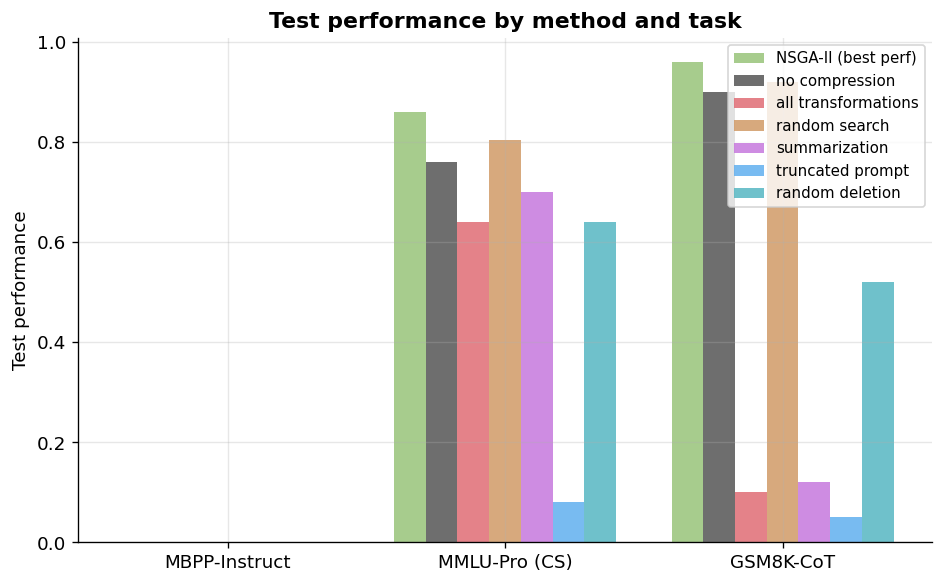

In [13]:
# Bar chart: test performance per method per task
if table_rows:
    df_plot = pd.DataFrame(table_rows)
    df_plot["Test perf"] = df_plot["Test perf"].astype(float)

    methods = df_plot["Method"].unique().tolist()
    tasks   = [TASK_LABELS[n] for n in RUNS if n in results]

    x      = np.arange(len(tasks))
    width  = 0.8 / len(methods)

    fig, ax = plt.subplots(figsize=(max(8, 2 * len(tasks)), 5))
    for i, method in enumerate(methods):
        sub  = df_plot[df_plot["Method"] == method].set_index("Task")
        vals = [sub.loc[t, "Test perf"] if t in sub.index else float("nan") for t in tasks]
        key  = method.replace(" ", "_")
        color = BASELINE_STYLE.get(key, {}).get("color", "#aaaaaa")
        if method.startswith("NSGA"):
            color = "#98c379"
        ax.bar(x + i * width, vals, width, label=method, color=color, alpha=0.85)

    ax.set_xticks(x + width * (len(methods) - 1) / 2)
    ax.set_xticklabels(tasks)
    ax.set_ylabel("Test performance")
    ax.set_title("Test performance by method and task", fontweight="bold")
    ax.legend(loc="upper right", fontsize=9)
    plt.tight_layout()
    plt.show()
else:
    print("No data yet.")

## 4. Compression ratio vs. performance

**Compression ratio** = (tokens after) / (tokens before, i.e. `no_compression` baseline).  
A ratio < 1 means the prompt got shorter.  Each point is one Pareto solution or baseline;
tasks are colour-coded.

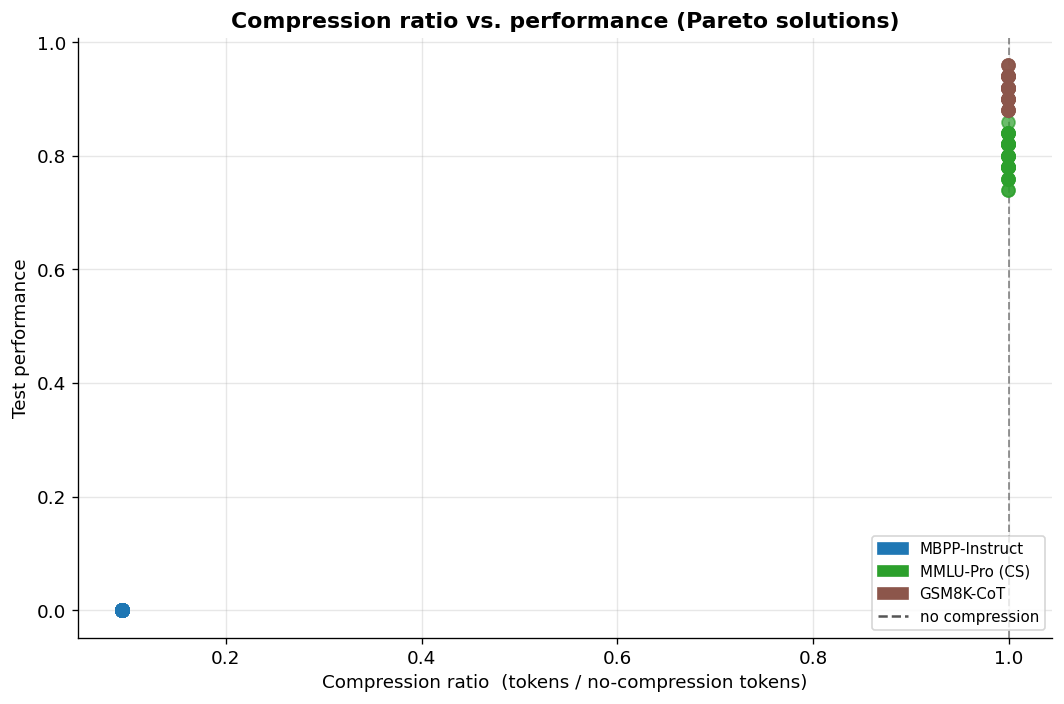

In [14]:
task_colors = plt.cm.tab10(np.linspace(0, 1, len(RUNS)))
task_color_map = {name: task_colors[i] for i, name in enumerate(RUNS)}

fig, ax = plt.subplots(figsize=(9, 6))
legend_patches = []
any_data = False

for name in RUNS:
    if name not in results:
        continue
    r     = results[name]
    label = TASK_LABELS.get(name, name)
    color = task_color_map[name]
    any_data = True

    # Reference token count from no_compression baseline
    ref_tok = next(
        (bl.get("test_avg_tokens") or bl["search_avg_tokens"]
         for bl in r["baselines"] if bl["name"] == "no_compression"),
        None,
    )
    if ref_tok is None or ref_tok == 0:
        continue

    # Pareto solutions
    for sol in r["pareto_solutions"]:
        tok  = sol.get("test_avg_tokens")       or sol["search_avg_tokens"]
        perf = sol.get("test_avg_performance")  or sol["search_avg_performance"]
        ax.scatter(tok / ref_tok, perf, color=color, s=60, alpha=0.7, zorder=4)

    legend_patches.append(mpatches.Patch(color=color, label=label))

# Draw a vertical reference line at ratio=1 (no compression)
ax.axvline(1.0, color="#555555", lw=1.2, ls="--", alpha=0.6, label="no compression")

if any_data:
    ax.set_xlabel("Compression ratio  (tokens / no-compression tokens)")
    ax.set_ylabel("Test performance")
    ax.set_title("Compression ratio vs. performance (Pareto solutions)", fontweight="bold")
    ax.legend(handles=legend_patches + [plt.Line2D([0], [0], color='#555555',
              ls='--', label='no compression')],
              loc="lower right", fontsize=9)
    plt.tight_layout()
    plt.show()
else:
    print("No data yet.")

## 5. Convergence

For each completed run, shows how the best performance in the Pareto front and the number
of non-dominated solutions evolve across generations.

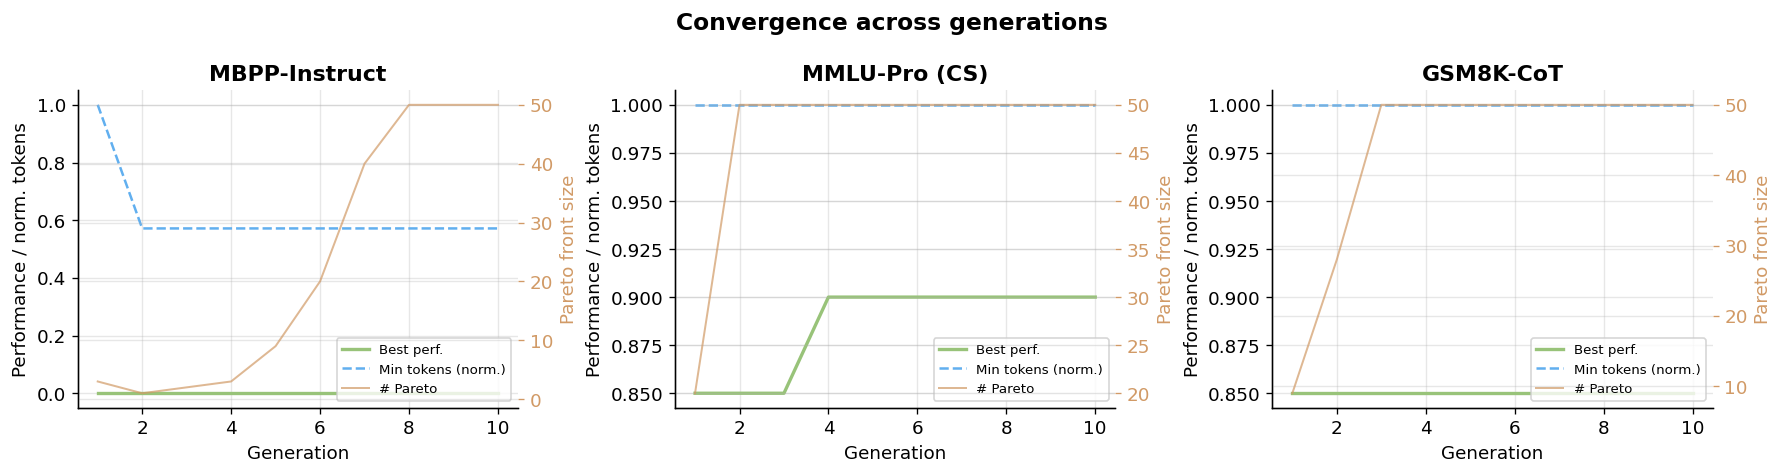

In [15]:
runs_with_history = [
    n for n in RUNS
    if n in results and results[n].get("generation_history")
]

if not runs_with_history:
    print("No generation history available yet.")
else:
    ncols = min(3, len(runs_with_history))
    nrows = (len(runs_with_history) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)

    for idx, name in enumerate(runs_with_history):
        ax  = axes[idx // ncols][idx % ncols]
        ax2 = ax.twinx()
        history = results[name]["generation_history"]

        gens      = [h["generation"]  for h in history]
        n_sols    = [h["n_solutions"] for h in history]
        best_perf = [
            max((s["avg_performance"] for s in h["pareto_front"]), default=float("nan"))
            for h in history
        ]
        min_tok   = [
            min((s["avg_tokens"] for s in h["pareto_front"]), default=float("nan"))
            for h in history
        ]

        ax.plot(gens, best_perf, color="#98c379", lw=2, label="Best perf.")
        ax.plot(gens, [t / max(min_tok + [1]) for t in min_tok],
                color="#61afef", lw=1.5, ls="--", label="Min tokens (norm.)")
        ax2.plot(gens, n_sols, color="#d19a66", lw=1.2, alpha=0.7, label="# Pareto")

        ax.set_xlabel("Generation")
        ax.set_ylabel("Performance / norm. tokens")
        ax2.set_ylabel("Pareto front size", color="#d19a66")
        ax2.tick_params(axis="y", colors="#d19a66")
        ax.set_title(TASK_LABELS.get(name, name), fontweight="bold")

        lines1, labels1 = ax.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc="lower right")

    for idx in range(len(runs_with_history), nrows * ncols):
        axes[idx // ncols][idx % ncols].set_visible(False)

    fig.suptitle("Convergence across generations", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

## 6. Operator usage

For each task, how often does each transformation appear in the Pareto-optimal solutions
(as a fraction of all Pareto solutions for that task).  Operators that never appear in any
Pareto front are omitted.

In [16]:
if not completed:
    print("No completed runs yet.")
else:
    # Collect all operator names across all tasks
    all_ops = []
    for name in completed:
        all_ops.extend(results[name].get("transformation_names", []))
    all_ops = list(dict.fromkeys(all_ops))  # unique, order-preserving

    task_labels = [TASK_LABELS.get(n, n) for n in completed]
    usage = np.zeros((len(all_ops), len(completed)))

    for j, name in enumerate(completed):
        r    = results[name]
        sols = r["pareto_solutions"]
        if not sols:
            continue
        op_idx = {op: i for i, op in enumerate(all_ops)}
        for sol in sols:
            for op in sol.get("transformation_names", []):
                if op in op_idx:
                    usage[op_idx[op], j] += 1
        usage[:, j] /= len(sols)   # normalise to [0, 1]

    # Drop operators with zero usage across all tasks
    active = np.any(usage > 0, axis=1)
    usage_active = usage[active]
    ops_active   = [op for op, a in zip(all_ops, active) if a]

    if len(ops_active) == 0:
        print("No Pareto solutions with non-zero operator usage found.")
    else:
        fig, ax = plt.subplots(figsize=(max(6, len(completed) * 1.4),
                                        max(4, len(ops_active) * 0.35)))
        im = ax.imshow(usage_active, aspect="auto", cmap="YlOrRd",
                       vmin=0, vmax=1, interpolation="nearest")
        ax.set_xticks(range(len(task_labels)))
        ax.set_xticklabels(task_labels, rotation=30, ha="right")
        ax.set_yticks(range(len(ops_active)))
        ax.set_yticklabels(ops_active, fontsize=9)
        plt.colorbar(im, ax=ax, label="Fraction of Pareto solutions")
        ax.set_title("Operator usage across Pareto-optimal solutions", fontweight="bold")
        plt.tight_layout()
        plt.show()

No Pareto solutions with non-zero operator usage found.


## 7. Fitting report summary

What the `DatasetVocabularyFitter` discovered for each completed task.

In [17]:
for name in completed:
    r = results[name]
    report = r.get("fitting_report")
    if not report:
        continue
    label = TASK_LABELS.get(name, name)
    print(f"{'─'*60}")
    print(f"  {label}")
    print(f"{'─'*60}")
    for key, val in report.items():
        if isinstance(val, list):
            print(f"  {key} ({len(val)}): {val[:8]}{'...' if len(val) > 8 else ''}")
        else:
            print(f"  {key}: {val}")
    print()

────────────────────────────────────────────────────────────
  MBPP-Instruct
────────────────────────────────────────────────────────────
  labels: {'assert check_solution(1,3,2) == "yes"\nassert check_solution(1,2,3) == "no"\nassert check_solution(1,-5,6) == "no"': 'AC="AC="AC="', 'assert extract([[1, 2], [3, 4, 5], [6, 7, 8, 9]]) == [1, 3, 6]\nassert extract([[1,2,3],[4, 5]]) == [1,4]\nassert extract([[9,8,1],[1,2]]) == [9,1]': 'AE2[45[789=[36AE5=[AE=[', "assert find_max([['a'],['a','b'],['a','b','c']]) == ['a','b','c']\nassert find_max([[1],[1,2],[1,2,3]]) == [1,2,3]\nassert find_max([[1,1],[1,2,3],[1,5,6,1]]) == [1,5,6,1]": 'AF=[AF=[AF=[', "assert find_min([[1],[1,2],[1,2,3]]) == [1]\nassert find_min([[1,1],[1,1,1],[1,2,7,8]]) == [1,1]\nassert find_min([['x'],['x','y'],['x','y','z']]) == ['x']": 'AF=[AF=[AF=[', 'assert find_min_length([[1],[1,2]]) == 1\nassert find_min_length([[1,2],[1,2,3],[1,2,3,4]]) == 2\nassert find_min_length([[3,3,3],[4,4,4,4]]) == 3': 'AF=1AF=2AF=3', 'assert

## 8. NSGA-II vs MAB comparison

Direct comparison of the NSGA-II (evolutionary) and MAB (Thompson Sampling)
primary algorithms.  Each subplot shows the Pareto front of both methods for
one task.  Both use the same evaluation budget (``pop_size × n_gen``).

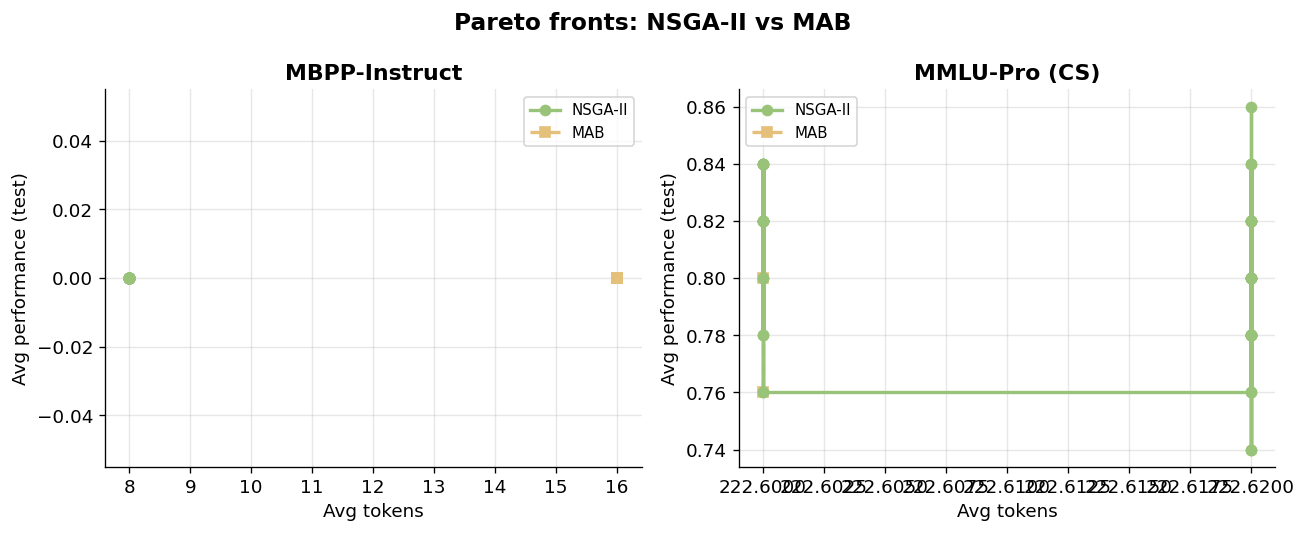

In [18]:
# ── 8a: Pareto front overlay — NSGA-II (green) vs MAB (orange) ──────────────
def _pareto_xy(solutions, split='test'):
    tok  = [s.get(f'{split}_avg_tokens')      or s['search_avg_tokens']      for s in solutions]
    perf = [s.get(f'{split}_avg_performance') or s['search_avg_performance'] for s in solutions]
    return np.array(tok), np.array(perf)

completed_nsga = [n for n in RUNS if n in results]
completed_mab  = [n for n in MAB_RUNS if n in mab_results]
# Pair up tasks that have both results
paired = [(n, n.replace('_nsga2', '_mab'))
          for n in completed_nsga if n.replace('_nsga2', '_mab') in mab_results]

if not paired:
    print('No paired NSGA-II + MAB results available yet.')
else:
    ncols = min(3, len(paired))
    nrows = (len(paired) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5*ncols, 4.5*nrows), squeeze=False)

    for idx, (nsga_name, mab_name) in enumerate(paired):
        ax    = axes[idx // ncols][idx % ncols]
        r_n   = results[nsga_name]
        r_m   = mab_results[mab_name]

        tok_n, perf_n = _pareto_xy(r_n['pareto_solutions'])
        ord_n = np.argsort(tok_n)
        ax.plot(tok_n[ord_n], perf_n[ord_n], 'o-', color='#98c379', lw=2,
                markersize=6, label='NSGA-II', zorder=6)

        tok_m, perf_m = _pareto_xy(r_m['pareto_solutions'])
        ord_m = np.argsort(tok_m)
        ax.plot(tok_m[ord_m], perf_m[ord_m], 's--', color='#e5c07b', lw=2,
                markersize=6, label='MAB', zorder=5)

        ax.set_title(TASK_LABELS.get(nsga_name, nsga_name), fontweight='bold')
        ax.set_xlabel('Avg tokens')
        ax.set_ylabel('Avg performance (test)')
        ax.legend(fontsize=9)

    for idx in range(len(paired), nrows * ncols):
        axes[idx // ncols][idx % ncols].set_visible(False)

    fig.suptitle('Pareto fronts: NSGA-II vs MAB', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


In [19]:
# ── 8b: Best-performance comparison table ────────────────────────────────────
cmp_rows = []
for nsga_name, mab_name in paired:
    label = TASK_LABELS.get(nsga_name, nsga_name)
    for alg, r in [('NSGA-II', results[nsga_name]), ('MAB', mab_results[mab_name])]:
        sols = r['pareto_solutions']
        if not sols:
            continue
        best = max(sols, key=lambda s: s.get('test_avg_performance') or s['search_avg_performance'])
        cmp_rows.append({
            'Task': label, 'Algorithm': alg,
            'Best test perf': best.get('test_avg_performance') or best['search_avg_performance'],
            'Tokens (best perf)': best.get('test_avg_tokens') or best['search_avg_tokens'],
            'Pareto size': len(sols),
        })

if cmp_rows:
    df_cmp = pd.DataFrame(cmp_rows)
    df_cmp['Best test perf'] = df_cmp['Best test perf'].map('{:.4f}'.format)
    df_cmp['Tokens (best perf)'] = df_cmp['Tokens (best perf)'].map('{:.1f}'.format)
    display(df_cmp.set_index(['Task', 'Algorithm']))
else:
    print('No data yet.')


Best test perf Tokens (best perf)  Pareto size
Task          Algorithm                                               
MBPP-Instruct NSGA-II           0.0000                8.0           50
              MAB               0.0000               16.0            6
MMLU-Pro (CS) NSGA-II           0.8600              222.6           50
              MAB               0.8000              222.6            2

## 9. Transferability analysis

Pareto solutions discovered for **GSM8K-CoT** are re-evaluated on **BBH-Logical**
(and vice versa) to measure cross-task generalisation.  A compression strategy that
transfers well sits close to the native Pareto front of the target task.

Each scatter plot shows three sets of points:
- **Native** (green circles): target-task NSGA-II Pareto solutions on the target task.
- **Transferred** (orange triangles): *source*-task Pareto solutions re-evaluated on the target task.
- **No-compression** reference (grey diamond).

In [ ]:
# ── 9: Transferability scatter ────────────────────────────────────────────────
if not transfer_results:
    print('No transferability results available yet — run the experiments first.')
else:
    npairs = len(transfer_results)
    ncols  = min(2, npairs)
    nrows  = (npairs + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 5*nrows), squeeze=False)

    for idx, ((src, tgt), te) in enumerate(transfer_results.items()):
        ax = axes[idx // ncols][idx % ncols]
        tgt_label = TASK_LABELS.get(tgt, tgt)
        src_label = TASK_LABELS.get(src, src)

        # Native Pareto front of target task
        if tgt in results:
            native_sols = results[tgt]['pareto_solutions']
            nat_tok  = [s.get('test_avg_tokens')       or s['search_avg_tokens']      for s in native_sols]
            nat_perf = [s.get('test_avg_performance')  or s['search_avg_performance'] for s in native_sols]
            ax.scatter(nat_tok, nat_perf, s=80, color='#98c379', marker='o',
                       label='Native (target)', zorder=6, alpha=0.9)

        # Transferred solutions (source Pareto evaluated on target task)
        tr_tok  = [s.get('test_avg_tokens')       or s['search_avg_tokens']      for s in te['solutions']]
        tr_perf = [s.get('test_avg_performance')  or s['search_avg_performance'] for s in te['solutions']]
        ax.scatter(tr_tok, tr_perf, s=80, color='#e5c07b', marker='^',
                   label=f'Transferred (from {src_label})', zorder=5, alpha=0.9)

        # No-compression reference from target run
        if tgt in results:
            ref_bl = next((b for b in results[tgt]['baselines'] if b['name'] == 'no_compression'), None)
            if ref_bl:
                ref_tok  = ref_bl.get('test_avg_tokens')       or ref_bl['search_avg_tokens']
                ref_perf = ref_bl.get('test_avg_performance')  or ref_bl['search_avg_performance']
                ax.scatter(ref_tok, ref_perf, s=120, color='#555555', marker='D',
                           label='No compression', zorder=7)

        ax.set_title(f'Source: {src_label}  →  Target: {tgt_label}', fontweight='bold', fontsize=10)
        ax.set_xlabel('Avg tokens (target task)')
        ax.set_ylabel('Avg performance (target task)')
        ax.legend(fontsize=8)

    for idx in range(npairs, nrows * ncols):
        axes[idx // ncols][idx % ncols].set_visible(False)

    fig.suptitle('Transferability: Pareto solutions across tasks', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
